# Estimating the volatility $\sigma$ through an inverse problem (Black–Scholes)

We look for the volatility $\sigma$ from observed prices of a European call.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Parameters and mesh

`sigma_true` is used **only** to generate the observations; the algorithm never sees it.

In [ ]:
sigma_true = 0.25   # volatility to recover
r = 0.03            # risk-free rate
K = 100             # strike
T = 1               # maturity
L = 400             # upper bound replacing infinity
Nx = 100            # number of space intervals
N = 100             # number of time intervals

Finite-difference matrices:
- `A` $=(-1,\,2,\,-1)$ corresponds to $-\Delta x^2\,\partial_{xx}$,
- `D` $=(-\tfrac12,\,0,\,\tfrac12)$ corresponds to $\Delta x\,\partial_x$.

In [ ]:
def mesh(Nx, N):
    x = np.linspace(0, L, Nx + 1)
    t = np.linspace(0, T, N + 1)
    return x, t, L / Nx, T / N


def fd_matrices(x):
    n = len(x)
    I = np.eye(n)
    A = 2 * np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1)
    D = (np.eye(n, k=1) - np.eye(n, k=-1)) / 2
    XXA = np.diag(x**2) @ A
    XD = np.diag(x) @ D
    return I, XXA, XD


def dirichlet_rows(B):

    B = B.copy()
    B[0, :] = 0
    B[0, 0] = 1
    B[-1, :] = 0
    B[-1, -1] = 1
    return B

## 2. Direct problem

$$\partial_t u + \tfrac12\sigma^2x^2\partial_{xx}u + rx\,\partial_x u - ru = 0,\qquad
u(x,T)=(x-K)^+,\quad u(0,t)=0,\quad u(L,t)=L-Ke^{-r(T-t)}.$$

### 2.1 Crank–Nicolson

$$\Big(I-\tfrac{\Delta t}{2}L_h\Big)U^n=\Big(I+\tfrac{\Delta t}{2}L_h\Big)U^{n+1}$$

In [ ]:
def solve_cn(sigma, Nx=Nx, N=N):
    x, t, dx, dt = mesh(Nx, N)
    I, XXA, XD = fd_matrices(x)
    Lh = -sigma**2 / 2 * XXA / dx**2 + r * XD / dx - r * I

    B = dirichlet_rows(I - dt / 2 * Lh)
    C = I + dt / 2 * Lh

    u = np.zeros((N + 1, Nx + 1))
    u[N] = np.maximum(x - K, 0)            # terminal condition (payoff)
    for n in range(N - 1, -1, -1):
        b = C @ u[n + 1]
        b[0] = 0                           # u(0, t) = 0
        b[-1] = L - K * np.exp(-r * (T - t[n]))   # u(L, t)
        u[n] = np.linalg.solve(B, b)
    return u

### 2.2 $P_1$ finite elements (complete weak formulation)

$M\dot U = K_h U$ with $K_h=\tfrac12\sigma^2S+(\sigma^2-r)C+rM$, then Crank–Nicolson in time.

In [ ]:
def solve_fem(sigma, Nx=Nx, N=N):
    x, t, dx, dt = mesh(Nx, N)
    M = np.zeros((Nx + 1, Nx + 1))
    S = np.zeros((Nx + 1, Nx + 1))
    C = np.zeros((Nx + 1, Nx + 1))
    for k in range(Nx):                    # element-by-element assembly
        h = x[k + 1] - x[k]
        xm = (x[k] + x[k + 1]) / 2
        Mloc = h / 6 * np.array([[2, 1], [1, 2]])
        Sloc = xm**2 / h * np.array([[1, -1], [-1, 1]])
        Cloc = xm / 2 * np.array([[-1, 1], [-1, 1]])
        for a in range(2):
            for b in range(2):
                M[k + a, k + b] += Mloc[a, b]
                S[k + a, k + b] += Sloc[a, b]
                C[k + a, k + b] += Cloc[a, b]

    Kh = 0.5 * sigma**2 * S + (sigma**2 - r) * C + r * M
    A = M + dt / 2 * Kh
    B = M - dt / 2 * Kh
    A[0, :] = 0
    A[0, 0] = 1
    A[Nx, :] = 0
    A[Nx, Nx] = 1

    u = np.zeros((N + 1, Nx + 1))
    u[N] = np.maximum(x - K, 0)
    for n in range(N - 1, -1, -1):
        b = B @ u[n + 1]
        b[0] = 0
        b[-1] = L - K * np.exp(-r * (T - t[n]))
        u[n] = np.linalg.solve(A, b)
    return u

### 2.3 Exact Black–Scholes solution

In [ ]:
def exact_price(x, tau, sigma):

    price = np.zeros_like(x)
    m = x > 0
    d1 = (np.log(x[m] / K) + (r + sigma**2 / 2) * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)
    price[m] = x[m] * norm.cdf(d1) - K * np.exp(-r * tau) * norm.cdf(d2)
    return price

## 3. Validation of the direct problem

### 3.1 Solution and price at the strike

Price at x = K, t = 0:  CN = 11.3174   FEM = 11.3368   exact = 11.3485


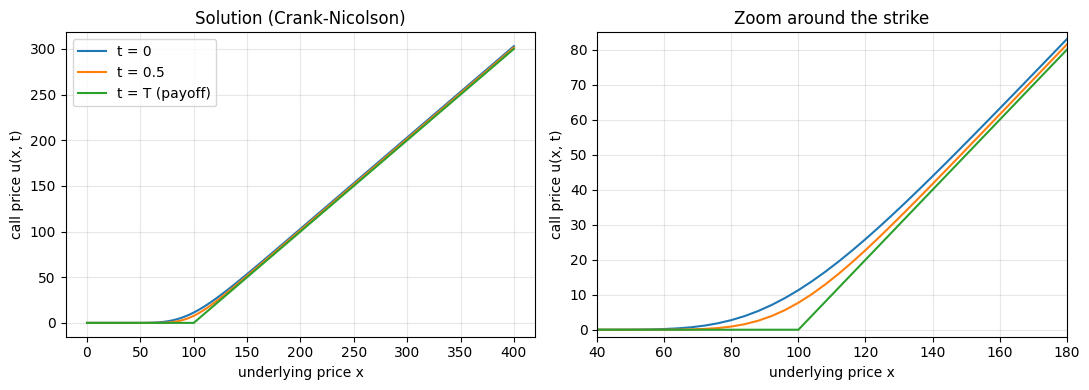

In [ ]:
x, t, dx, dt = mesh(Nx, N)
u_cn = solve_cn(sigma_true)
u_fem = solve_fem(sigma_true)
u_ex = exact_price(x, T, sigma_true)

iK = 25   # x[25] = K = 100
print(f"Price at x = K, t = 0:  CN = {u_cn[0, iK]:.4f}   FEM = {u_fem[0, iK]:.4f}   exact = {u_ex[iK]:.4f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax in axs:
    ax.plot(x, u_cn[0], label="t = 0")
    ax.plot(x, u_cn[N // 2], label="t = 0.5")
    ax.plot(x, u_cn[N], label="t = T (payoff)")
    ax.set_xlabel("underlying price x")
    ax.set_ylabel("call price u(x, t)")
axs[1].set_xlim(40, 180)
axs[1].set_ylim(-2, 85)
axs[0].set_title("Solution (Crank-Nicolson)")
axs[1].set_title("Zoom around the strike")
axs[0].legend()
plt.tight_layout()
plt.show()

### 3.2 Error at $t=0$

The error is largest around the strike, where the payoff has a kink.

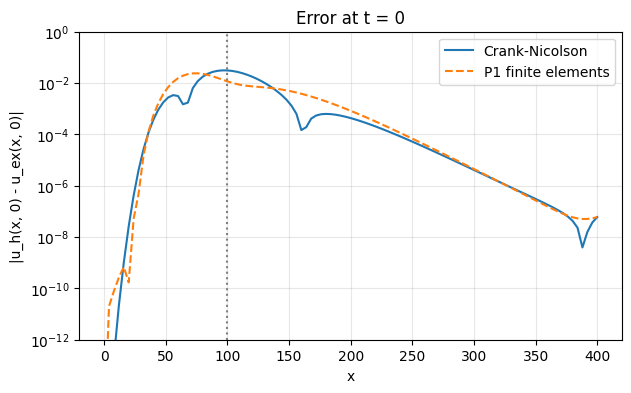

In [ ]:
plt.figure(figsize=(7, 4))
plt.semilogy(x, abs(u_cn[0] - u_ex) + 1e-16, label="Crank-Nicolson")
plt.semilogy(x, abs(u_fem[0] - u_ex) + 1e-16, "--", label="P1 finite elements")
plt.axvline(K, color="gray", ls=":")
plt.ylim(1e-12, 1)
plt.xlabel("x")
plt.ylabel("|u_h(x, 0) - u_ex(x, 0)|")
plt.title("Error at t = 0")
plt.legend()
plt.show()

### 3.3 Convergence study

We refine space and time together ($N=N_x$). The order is the slope of the line on a log-log scale.

L2 order   : CN = 2.00   FEM = 2.00
Linf order : CN = 2.00   FEM = 2.00


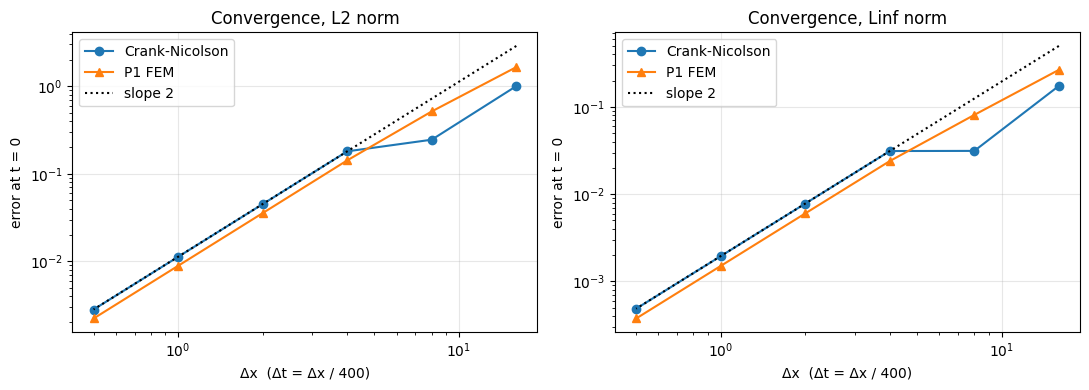

In [ ]:
list_Nx = [25, 50, 100, 200, 400, 800]
steps = np.array([L / n for n in list_Nx])
err_cn_L2, err_cn_inf, err_fem_L2, err_fem_inf = [], [], [], []

for n in list_Nx:
    xn, _, dxn, _ = mesh(n, n)
    exact = exact_price(xn, T, sigma_true)
    e_cn = solve_cn(sigma_true, n, n)[0] - exact
    e_fem = solve_fem(sigma_true, n, n)[0] - exact
    err_cn_L2.append(np.sqrt(dxn * np.sum(e_cn**2)))
    err_cn_inf.append(np.max(abs(e_cn)))
    err_fem_L2.append(np.sqrt(dxn * np.sum(e_fem**2)))
    err_fem_inf.append(np.max(abs(e_fem)))

def order(err):

    return np.polyfit(np.log(steps[2:]), np.log(err[2:]), 1)[0]

print(f"L2 order   : CN = {order(err_cn_L2):.2f}   FEM = {order(err_fem_L2):.2f}")
print(f"Linf order : CN = {order(err_cn_inf):.2f}   FEM = {order(err_fem_inf):.2f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, e_cn, e_fem, name in [(axs[0], err_cn_L2, err_fem_L2, "L2"),
                              (axs[1], err_cn_inf, err_fem_inf, "Linf")]:
    ax.loglog(steps, e_cn, "o-", label="Crank-Nicolson")
    ax.loglog(steps, e_fem, "^-", label="P1 FEM")
    ax.loglog(steps, e_cn[2] * (steps / steps[2])**2, "k:", label="slope 2")
    ax.set_xlabel("Δx  (Δt = Δx / 400)")
    ax.set_ylabel("error at t = 0")
    ax.set_title(f"Convergence, {name} norm")
    ax.legend()
plt.tight_layout()
plt.show()

## 4. Inverse problem

### 4.1 Noisy observations

$u_{\text{obs}} = u^\ast\,(1 + a\,\xi)$, with $\xi\sim\mathcal N(0,1)$ and $a = 2\,\%$.

In [ ]:
rng = np.random.default_rng(40)
u_obs = solve_cn(sigma_true)
u_obs[:, 1:-1] *= 1 + 0.02 * rng.standard_normal(u_obs[:, 1:-1].shape)

### 4.2 Adjoint equation (marching forward from $0$ to $T$) and gradient

$$-\partial_t p + \tfrac12\sigma^2x^2\partial_{xx}p + (2\sigma^2-r)x\,\partial_x p + (\sigma^2-2r)p = u_{\text{obs}}-u,\qquad p(x,0)=0,\ p(0,t)=p(L,t)=0$$

$$J(\sigma)=\tfrac12\iint(u-u_{\text{obs}})^2,\qquad J'(\sigma)=\sigma\iint x^2\,\partial_{xx}u\;p$$

In [ ]:
def solve_adjoint(sigma, u, u_obs, Nx=Nx, N=N):
    x, t, dx, dt = mesh(Nx, N)
    I, XXA, XD = fd_matrices(x)
    Ladj = -sigma**2 / 2 * XXA / dx**2 + (2 * sigma**2 - r) * XD / dx + (sigma**2 - 2 * r) * I

    A = dirichlet_rows(I - dt / 2 * Ladj)
    B = I + dt / 2 * Ladj
    F = u - u_obs

    p = np.zeros_like(u)                   # p(x, 0) = 0
    for n in range(N):
        b = B @ p[n] + dt / 2 * (F[n] + F[n + 1])
        b[0] = 0
        b[-1] = 0
        p[n + 1] = np.linalg.solve(A, b)
    return p


def cost(u, u_obs):
    return 0.5 * np.sum((u - u_obs)**2) * dx * dt


def J_and_gradient(sigma, u_obs):

    u = solve_cn(sigma)
    p = solve_adjoint(sigma, u, u_obs)
    uxx = (u[:, 2:] - 2 * u[:, 1:-1] + u[:, :-2]) / dx**2
    grad = sigma * np.sum(x[1:-1]**2 * uxx * p[:, 1:-1]) * dx * dt
    return cost(u, u_obs), grad

Gradient check against a finite difference:

In [ ]:
s, h = 0.4, 1e-5
J, g_adjoint = J_and_gradient(s, u_obs)
g_fd = (cost(solve_cn(s + h), u_obs) - cost(solve_cn(s - h), u_obs)) / (2 * h)
print(f"adjoint = {g_adjoint:.1f}   finite differences = {g_fd:.1f}   gap = {abs(g_adjoint - g_fd) / abs(g_fd):.1%}")

adjoint = 6048.4   finite differences = 6073.7   gap = 0.4%


### 4.3 Shape of $J$

$J$ has a minimum near $0.25$, but it is **not convex** for $\sigma < 0.11$ ($J''<0$).

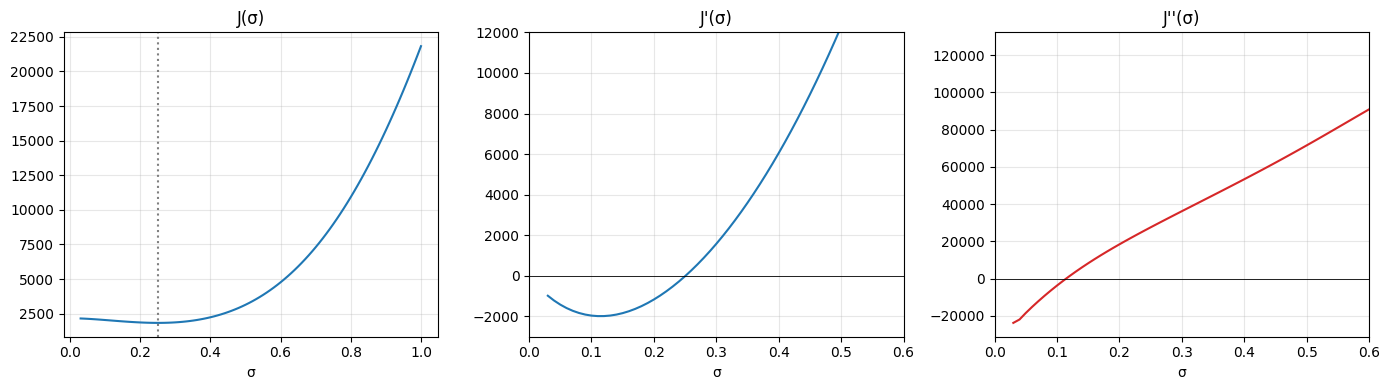

In [ ]:
sigmas = np.linspace(0.03, 1.0, 98)
values = np.array([J_and_gradient(s, u_obs) for s in sigmas])
J_vals, dJ_vals = values[:, 0], values[:, 1]
d2J_vals = np.gradient(dJ_vals, sigmas)

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
axs[0].plot(sigmas, J_vals)
axs[0].axvline(sigma_true, color="gray", ls=":")
axs[0].set_title("J(σ)")
axs[1].plot(sigmas, dJ_vals)
axs[1].axhline(0, color="k", lw=0.6)
axs[1].set_xlim(0, 0.6)
axs[1].set_ylim(-3000, 12000)
axs[1].set_title("J'(σ)")
axs[2].plot(sigmas, d2J_vals, color="C3")
axs[2].axhline(0, color="k", lw=0.6)
axs[2].set_xlim(0, 0.6)
axs[2].set_title("J''(σ)")
for ax in axs:
    ax.set_xlabel("σ")
plt.tight_layout()
plt.show()

## 5. Gradient descent

$\sigma_{k+1} = \sigma_k - \eta\,J'(\sigma_k)$, with $\eta = 10^{-5}$; stop when $|J'| < 10^{-5}$.

σ0 = 0.05:  σ* = 0.25055  in 69 iterations
σ0 = 0.2:  σ* = 0.25055  in 60 iterations
σ0 = 0.85:  σ* = 0.25055  in 62 iterations


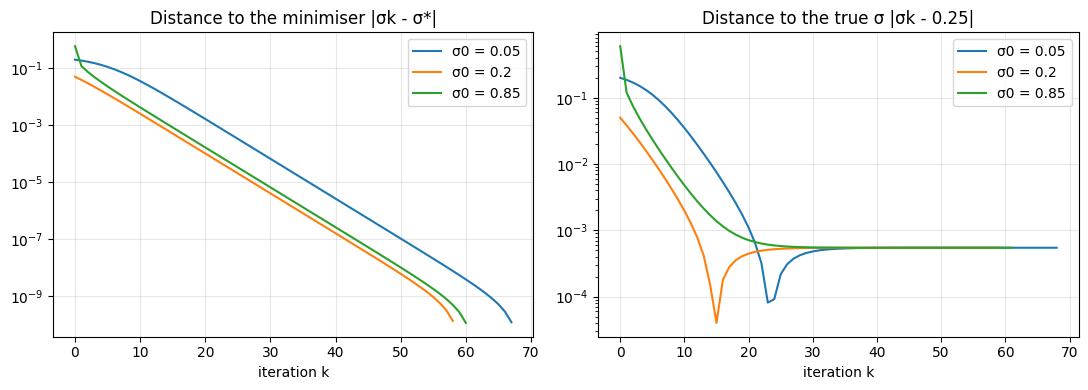

In [ ]:
def gradient_descent(sigma, u_obs, eta=1e-5, tol=1e-5, max_iter=2000):
    history = [sigma]
    for k in range(max_iter):
        J, grad = J_and_gradient(sigma, u_obs)
        if abs(grad) < tol:
            break
        sigma = sigma - eta * grad
        history.append(sigma)
    return np.array(history)


fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for s0 in [0.05, 0.20, 0.85]:
    hist = gradient_descent(s0, u_obs)
    print(f"σ0 = {s0}:  σ* = {hist[-1]:.5f}  in {len(hist)} iterations")
    axs[0].semilogy(abs(hist[:-1] - hist[-1]), label=f"σ0 = {s0}")
    axs[1].semilogy(abs(hist - sigma_true), label=f"σ0 = {s0}")
axs[0].set_title("Distance to the minimiser |σk - σ*|")
axs[1].set_title("Distance to the true σ |σk - 0.25|")
for ax in axs:
    ax.set_xlabel("iteration k")
    ax.legend()
plt.tight_layout()
plt.show()

We find $\sigma^\star \approx 0.2505$ whatever the value of $\sigma_0$. The gap with $0.25$ comes from the noise in the observations.

## 6. Newton–Raphson

$$\sigma_{k+1} = \sigma_k - \frac{J'(\sigma_k)}{J''(\sigma_k)},\qquad J''(\sigma)\approx\frac{J(\sigma+h)-2J(\sigma)+J(\sigma-h)}{h^2}$$

- **Step-size search**: we halve the step as long as $J$ does not decrease.
- **Safeguard**: if $J''\le 0$ (non-convex region), we take a small descent step instead.

In [ ]:
def newton(sigma, u_obs, tol=1e-6, max_iter=50, h=1e-4, safeguard=True):
    J_of = lambda s: cost(solve_cn(s), u_obs)
    history = [sigma]
    for k in range(max_iter):
        J, grad = J_and_gradient(sigma, u_obs)
        print(f"{k:2d}  σ = {sigma:.6f}   J = {J:.4e}   J' = {grad:.4e}")
        if abs(grad) < tol:
            break
        d2J = (J_of(sigma + h) - 2 * J + J_of(sigma - h)) / h**2
        if d2J > 0 or not safeguard:
            step = -grad / d2J
        else:
            step = -np.sign(grad) * 0.1 * sigma
        eta = 1.0
        while J_of(max(sigma + eta * step, 1e-8)) >= J:
            eta /= 2
            if eta < 1e-10:
                print("   step too small, stop.")
                return np.array(history)
        sigma = max(sigma + eta * step, 1e-8)
        history.append(sigma)
    return np.array(history)

### 6.1 Starting from $\sigma_0 = 0.9$

In [ ]:
hist_09 = newton(0.9, u_obs)

 0  σ = 0.900000   J = 1.5756e+04   J' = 5.4321e+04
 1  σ = 0.465000   J = 2.7537e+03   J' = 9.8896e+03
 2  σ = 0.313478   J = 1.8938e+03   J' = 2.0805e+03
 3  σ = 0.259600   J = 1.8328e+03   J' = 2.5706e+02
 4  σ = 0.250827   J = 1.8316e+03   J' = 7.7326e+00
 5  σ = 0.250549   J = 1.8316e+03   J' = 3.6715e-02
 6  σ = 0.250547   J = 1.8316e+03   J' = 1.4203e-04
 7  σ = 0.250547   J = 1.8316e+03   J' = 5.4892e-07


### 6.2 Starting from $\sigma_0 = 0.08$

Without the safeguard, Newton fails: at $0.08$, $J''<0$, so the step $-J'/J''$ makes $J$ **increase**.

In [ ]:
newton(0.08, u_obs, safeguard=False);

 0  σ = 0.080000   J = 2.0766e+03   J' = -1.8303e+03
   step too small, stop.


With the safeguard, it leaves the non-convex region and then converges:

In [ ]:
hist_008 = newton(0.08, u_obs)

 0  σ = 0.080000   J = 2.0766e+03   J' = -1.8303e+03
 1  σ = 0.088000   J = 2.0616e+03   J' = -1.8951e+03
 2  σ = 0.096800   J = 2.0447e+03   J' = -1.9459e+03
 3  σ = 0.106480   J = 2.0256e+03   J' = -1.9779e+03
 4  σ = 0.117128   J = 2.0044e+03   J' = -1.9853e+03
 5  σ = 0.311556   J = 1.8898e+03   J' = 2.0068e+03
 6  σ = 0.259137   J = 1.8327e+03   J' = 2.4356e+02
 7  σ = 0.250802   J = 1.8316e+03   J' = 7.0263e+00
 8  σ = 0.250549   J = 1.8316e+03   J' = 3.2795e-02
 9  σ = 0.250547   J = 1.8316e+03   J' = 1.2686e-04
10  σ = 0.250547   J = 1.8316e+03   J' = 4.9018e-07


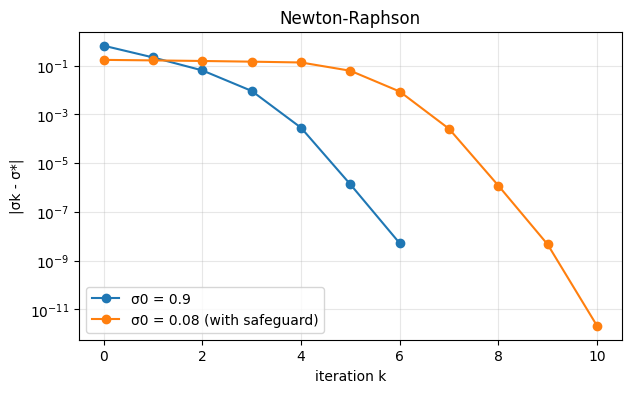

In [ ]:
sigma_star = hist_09[-1]
plt.figure(figsize=(7, 4))
for hist, name in [(hist_09, "σ0 = 0.9"), (hist_008, "σ0 = 0.08 (with safeguard)")]:
    gap = abs(hist - sigma_star)
    keep = gap > 1e-13
    plt.semilogy(np.arange(len(hist))[keep], gap[keep], "o-", label=name)
plt.xlabel("iteration k")
plt.ylabel("|σk - σ*|")
plt.title("Newton-Raphson")
plt.legend()
plt.show()

## Conclusion

- Crank–Nicolson and finite elements are both **second-order accurate**.
- The adjoint method gives $J'(\sigma)$ with **one** direct solve and **one** adjoint solve.
- Gradient descent and Newton find the **same** $\sigma^\star\approx0.2505$; Newton is about 10 times faster, but it must be safeguarded when $J''\le0$.